# 02 — Reconstrução da afluência líquida por balanço (períodos não saturados)
`I_net[t] = V[t+1] − V[t] + R`, com Z = 0 (sem vertimento) e E ≈ 0 (desconhecida). R = 5,3 m³/s constante (valor de notícia, ciclo 2026–27; **aproximação**). Dias saturados (V ≥ 1752,36) e dias com lacuna são excluídos.

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd, matplotlib.pyplot as plt
from src.data.loaders import load_portal_volume
from src.hydrology.water_balance import reconstruct_net_inflow

portal = load_portal_volume('../data/reserv-ors-capac-175236-portal-hidrologico-ce.csv')
res = {q: reconstruct_net_inflow(portal, q) for q in (4.5, 5.3)}
r = res[5.3]; v = r[r.valid]
print('dias válidos:', len(v), 'de', len(r), '| fração com I_net < 0:', round((v.I_net_hm3 < 0).mean(), 3))

dias válidos: 6795 de 7302 | fração com I_net < 0: 0.583


## 1. Sensibilidade a R e escala mensal
O ruído diário é grande (σ ≈ 3,8 hm³/dia); agregamos por mês e comparamos R = 4,5 e 5,3 m³/s.

meses com média negativa: 129 de 228


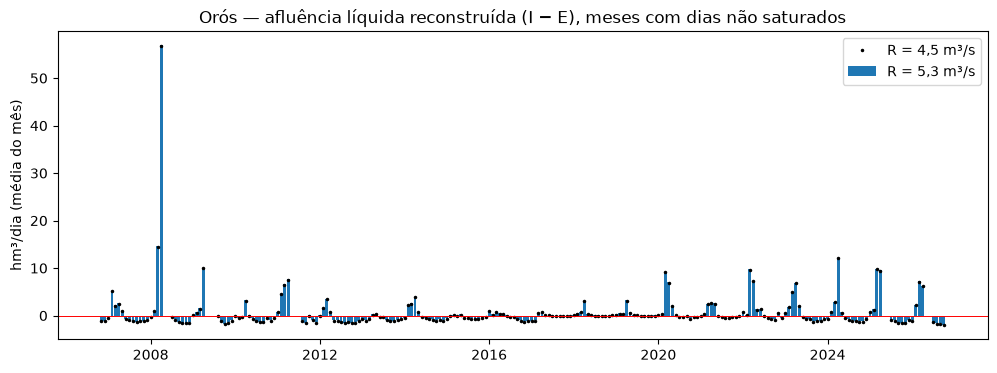

In [2]:
def monthly(rr):
    x = rr[rr.valid].copy(); x['m'] = x.date.dt.to_period('M')
    g = x.groupby('m').agg(days=('I_net_hm3', 'size'), I_net_hm3=('I_net_hm3', 'sum'))
    g['I_net_hm3_per_day'] = g.I_net_hm3 / g.days
    return g
m53, m45 = monthly(res[5.3]), monthly(res[4.5])
m53.to_csv('../data/processed/oros_net_inflow_monthly_R5.3.csv')
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(m53.index.to_timestamp(), m53.I_net_hm3_per_day, width=25, label='R = 5,3 m³/s')
ax.plot(m45.index.to_timestamp(), m45.I_net_hm3_per_day, 'k.', ms=3, label='R = 4,5 m³/s')
ax.axhline(0, color='r', lw=.7); ax.set_ylabel('hm³/dia (média do mês)'); ax.legend()
ax.set_title('Orós — afluência líquida reconstruída (I − E), meses com dias não saturados')
fig.savefig('../results/figures/02_net_inflow_monthly.png', dpi=150, bbox_inches='tight')
print('meses com média negativa:', int((m53.I_net_hm3_per_day < 0).sum()), 'de', len(m53))

## 2. Interpretação e limites
- **Fração alta de I_net < 0** (≈ 58 % dos dias): fisicamente a afluência não é negativa, então o balanço simplificado **subestima as saídas**. As causas possíveis são evaporação (E ≈ 0 aqui), retiradas reais diferentes de 5,3 m³/s, infiltração e erro de medição do volume. **Não** é um erro de código (conservação testada em `tests/test_water_balance.py`).
- Logo `I_net` **não é um limite inferior de afluência**; é `I − E − (R_real − R_assumido)`. Em meses secos, `−I_net` dá uma **estimativa do excesso de saídas não modeladas** (E + diferença de R), útil para calibrar E depois.
- Só tem boa informação de **afluência** nos meses de cheia, quando `I ≫ E`.
- O Portal usa a curva batimétrica da Cogerh; dias saturados (≈ 7 % da série, justamente os de maior afluência) ficam de fora, o que **enviesa** a série para baixo/normal.
- Próximo passo: estimar E (Penman + curva cota–área) e usar retiradas reais (Cogerh) para fechar o balanço.